# Supplementary Figure 5: error controls at different selection stages

Panels a-f show what each error control measures: the fusion-linked diagnostic in four cohorts (a-c), the explicit-peptide donor and self-selected entrapment controls (d) and the known-truth simulations (e,f). The continuation page decomposes the CAMPI fusion diagnostic into paired and unresolved parts. Every panel is redrawn from `source_data/SFig05/` with the v30 plotting code and compared pixel by pixel with the v30 render.

Run from the repository root: `python paper.py build SFig05`.

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()
import pandas as pd
from IPython.display import Image, display
T = panels.load(SD)

## Panels a-f

Panels a-f are drawn as one figure (`panels.figure_a_to_f`, which calls `panel_ab`, `panel_c`, `panel_d` and `panel_ef`), saved as PDF with `fl_style.save` and rasterised at 300 dpi, as in the v30 build.

- a,b: fusion-linked diagnostic at peptide q≤0.01 for 5-50 and 9-50 residues, split into paired and unresolved parts; one bar per cohort and seed. Unit: acquisition counts summed within cohort and seed (CAMPI 15, healthy stool 58, PREDICT 306, CapScan 331 acquisitions; two seeds). Descriptive, no test.
- c: nested 5-8-residue population, one dot per seed, bar at the median of the two seeds. Descriptive.
- d: explicit-peptide entrapment, self-selected (5 acquisitions) and donor-selected (58 acquisitions), each acquisition the mean of three seeds. Supports "The median entrapment estimate was 1.0% for accepted 5–50-residue peptides and 0.49% for the 9–50-residue subset" (visible_v30f line 30). Descriptive.
- e,f: realised false-discovery proportion in 12 baseline and 12 stress mixtures for the fixed, independent and self arms; squares are means with 95% whole-mixture percentile bootstrap intervals (20,000 resamples). Supports "did not increase the false-discovery proportion under baseline conditions (1.01% versus 1.25% with a fixed reference)" and "the proportion increased to 1.91%, 0.71 percentage points above selection from an independent replicate" (visible_v30f line 46). Unit: synthetic mixture, n = 12 per regime.

  [style] SFig05: 0 label(s) raised to 5 pt, 6 capped to 7 pt, 0 tick axis/axes clamped, 0 line(s) raised to 1 pt


<repo>/figures/SFig05/panels.py:211: UserWarning: SFig05.pdf is 160.00 mm wide, not 88 or 180 mm (nearest 180). compose.py will refuse it. If it is a near miss, the cause is almost always a bbox that cropped the canvas -- REDRAW at the placed width; do not scale and do not pad.
  fl.save(fig, out / 'SFig05', dpi=PNG_DPI, formats=('pdf',))


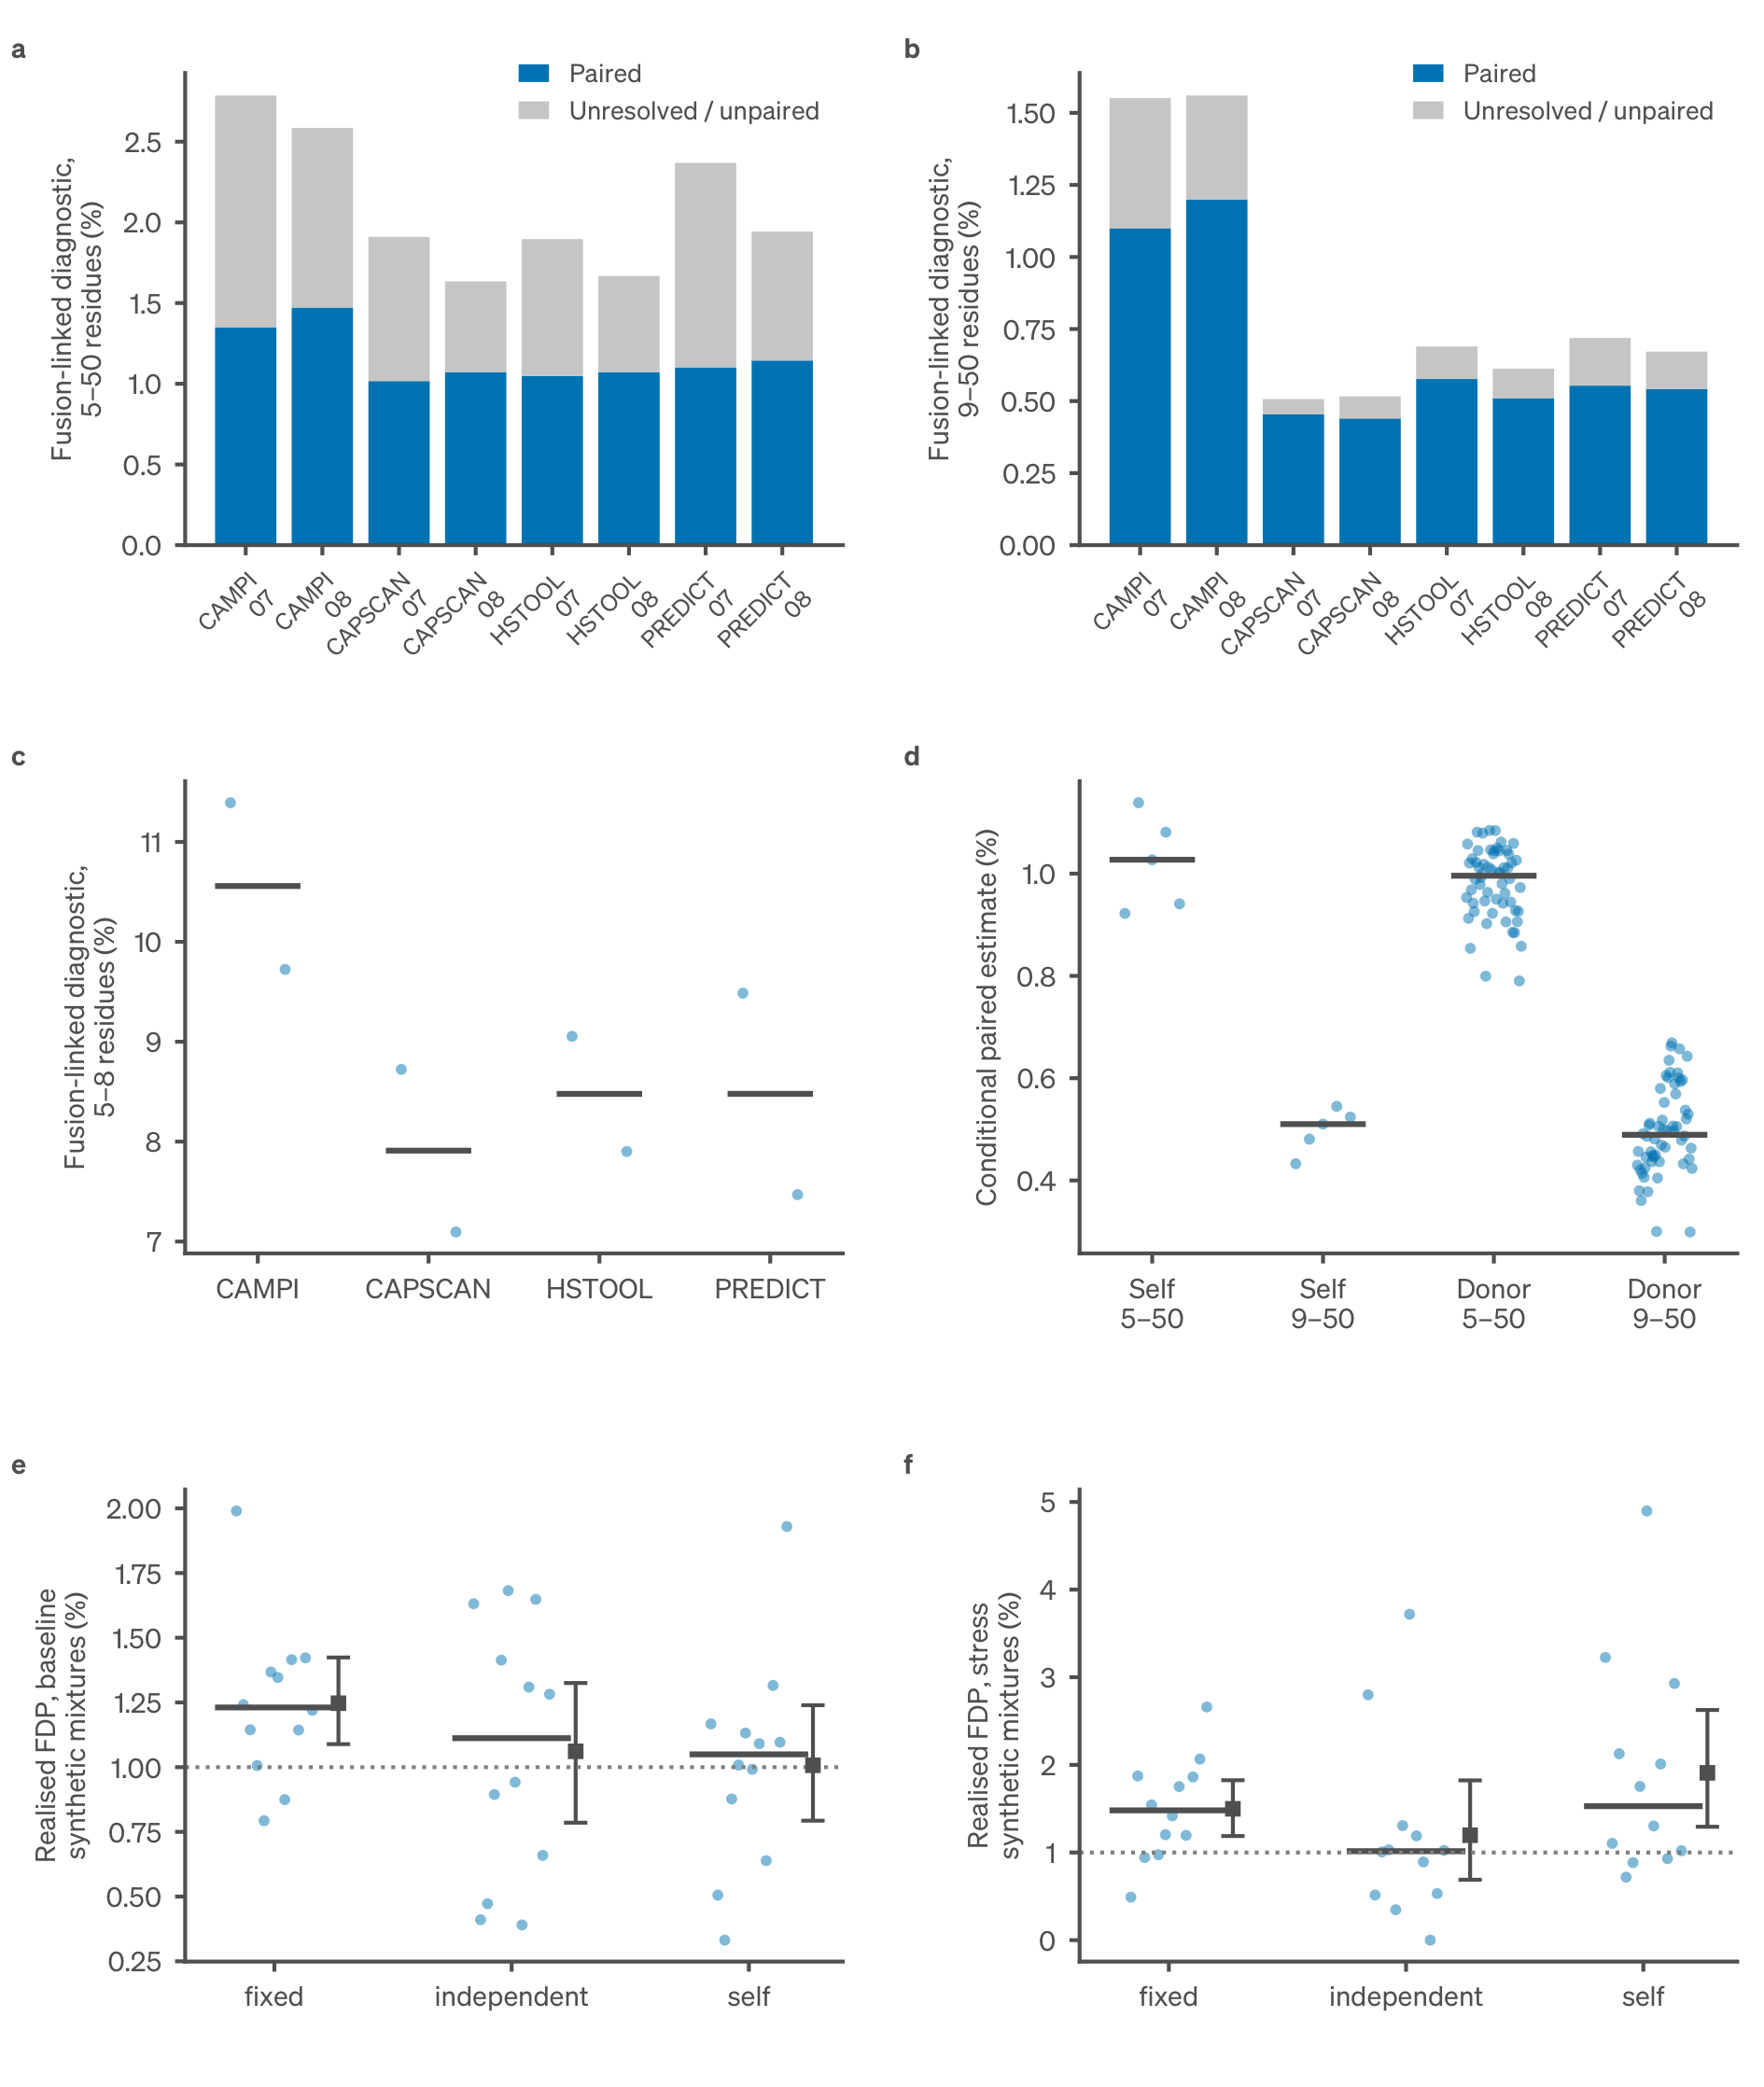

In [2]:
png = panels.figure_a_to_f(T, OUT)
display(Image(filename=str(png), width=700))

### Panels a-c: pooled values recomputed from acquisition components

Summing acquisition-level numerators and denominators within cohort and seed (Methods, visible_v30f line 367) reproduces every drawn value.

In [3]:
pooled = panels.stat_ac_fusion_pooled(T["fusion_acquisition_components"])
display(panels.compare_pooled(pooled, T["fusion_pooled_current"]))
display(pooled[pooled.q_threshold.eq(panels.Q_CUTOFF) & pooled.max_residues.eq(50)].groupby("cohort").acquisitions.first())

,column,rows,max_abs_difference
0,_merge,120,0.000000e+00
1,n_canonical,120,0.000000e+00
2,paired_numerator,120,0.000000e+00
3,n_unpaired_accepted,120,0.000000e+00
4,diagnostic,120,9.887924e-17
5,paired_component,120,9.887924e-17
6,unpaired_component,120,9.714451e-17
7,acquisitions,30,0.000000e+00
8,median_acquisition_diagnostic,30,9.454243e-17


cohort
CAMPI       15
CAPSCAN    331
HSTOOL      58
PREDICT    306
Name: acquisitions, dtype: int64

### Panel d: seed means and medians recomputed from per-seed records

In [4]:
seed_means = panels.stat_d_donor_seed_means(T["donor_recount"])
display(panels.compare_frames(seed_means, T["donor_entrapment_seed_means"], ["target", "donor", "tier", "group", "min_length", "q_threshold"]))
display(panels.stat_d_donor_summary(seed_means))

{'unmatched_rows': 0,
 'n_target': 7.275957614183426e-12,
 'n_entrapment': 5.684341886080802e-14,
 'paired_estimate': 9.996344030316351e-17,
 'lower_fraction': 9.996344030316351e-17,
 'combined_estimate': 9.996344030316351e-17}

,tier,min_length,acquisitions,median,q25,q75,minimum,maximum
0,T0_self,5,5,0.010272,0.009410,0.010811,0.009223,0.011387
1,T0_self,9,5,0.005102,0.004808,0.005241,0.004327,0.005450
2,T1_within_group,5,58,0.009958,0.009423,0.010360,0.007902,0.010846
3,T1_within_group,9,58,0.004893,0.004380,0.005650,0.002994,0.006693


### Panels e,f: bootstrap intervals recomputed

The bootstrap is rerun with the producer's generator, seed (2026091051) and draw order on all 288 simulation outcomes, of which the 72 ordinary outcomes are used.

In [5]:
unc = panels.stat_ef_simulation_uncertainty(T["simulation_all_outcomes"])
display(panels.compare_frames(unc, T["simulation_uncertainty"], ["regime", "endpoint"]))
print("max |FDP - false/max(discoveries,1)| over 72 outcomes:", panels.stat_ef_fdp_identity(T["simulation_mixture_outcomes"]))
display(unc)

{'unmatched_rows': 0,
 'n_units': 0.0,
 'mean': 9.020562075079397e-17,
 'bootstrap_low': 9.367506770274758e-17,
 'bootstrap_high': 6.938893903907228e-17,
 't_low': 9.80118763926896e-17,
 't_high': 7.28583859910259e-17,
 'total_discoveries': 0.0,
 'total_false': 0.0,
 'pooled_FDP': 9.367506770274758e-17}

max |FDP - false/max(discoveries,1)| over 72 outcomes: 9.71445146547012e-17


,regime,endpoint,n_units,mean,bootstrap_low,bootstrap_high,t_low,t_high,total_discoveries,total_false,pooled_FDP
0,baseline,fixed,12,0.012472,0.010889,0.014238,0.010499,0.014444,16736.0,209.0,0.012488
1,baseline,independent,12,0.010613,0.007854,0.013251,0.007458,0.013769,6780.0,73.0,0.010767
2,baseline,self,12,0.010072,0.007932,0.012394,0.007457,0.012686,6607.0,66.0,0.009989
3,stress,fixed,12,0.014989,0.011879,0.018245,0.011256,0.018721,10181.0,154.0,0.015126
4,stress,independent,12,0.011971,0.006891,0.018233,0.005283,0.018660,2903.0,36.0,0.012401
5,stress,self,12,0.019090,0.012940,0.026264,0.011188,0.026992,3112.0,58.0,0.018638
6,baseline,self_minus_independent,12,-0.000542,-0.002984,0.002000,-0.003472,0.002389,NaN,NaN,NaN
7,stress,self_minus_independent,12,0.007118,0.003523,0.011235,0.002604,0.011632,NaN,NaN,NaN


## Panel continued

Decomposition of the CAMPI fusion diagnostic: 15 acquisitions pooled separately for each seed from the 375,333,654-sequence reservoir at peptide q≤0.01. Blue is the weighted paired contribution (E + E₀ + 2B)/N, grey the unresolved contribution U/N; labels give the total. Supports Methods visible_v30f line 367 ("the pooled diagnostic was 2.59–2.79% for 5–50 residues and 1.55–1.56% for the nested 9–50-residue subset") and line 45 ("the pooled diagnostic averaged 1.6% for 9–50-residue peptides over two randomizations"). Unit: acquisition counts summed within seed (n = 15 per seed, two seeds). Descriptive, no test.

  [style] SFig05_continued: 0 label(s) raised to 5 pt, 0 capped to 7 pt, 0 tick axis/axes clamped, 1 line(s) raised to 1 pt


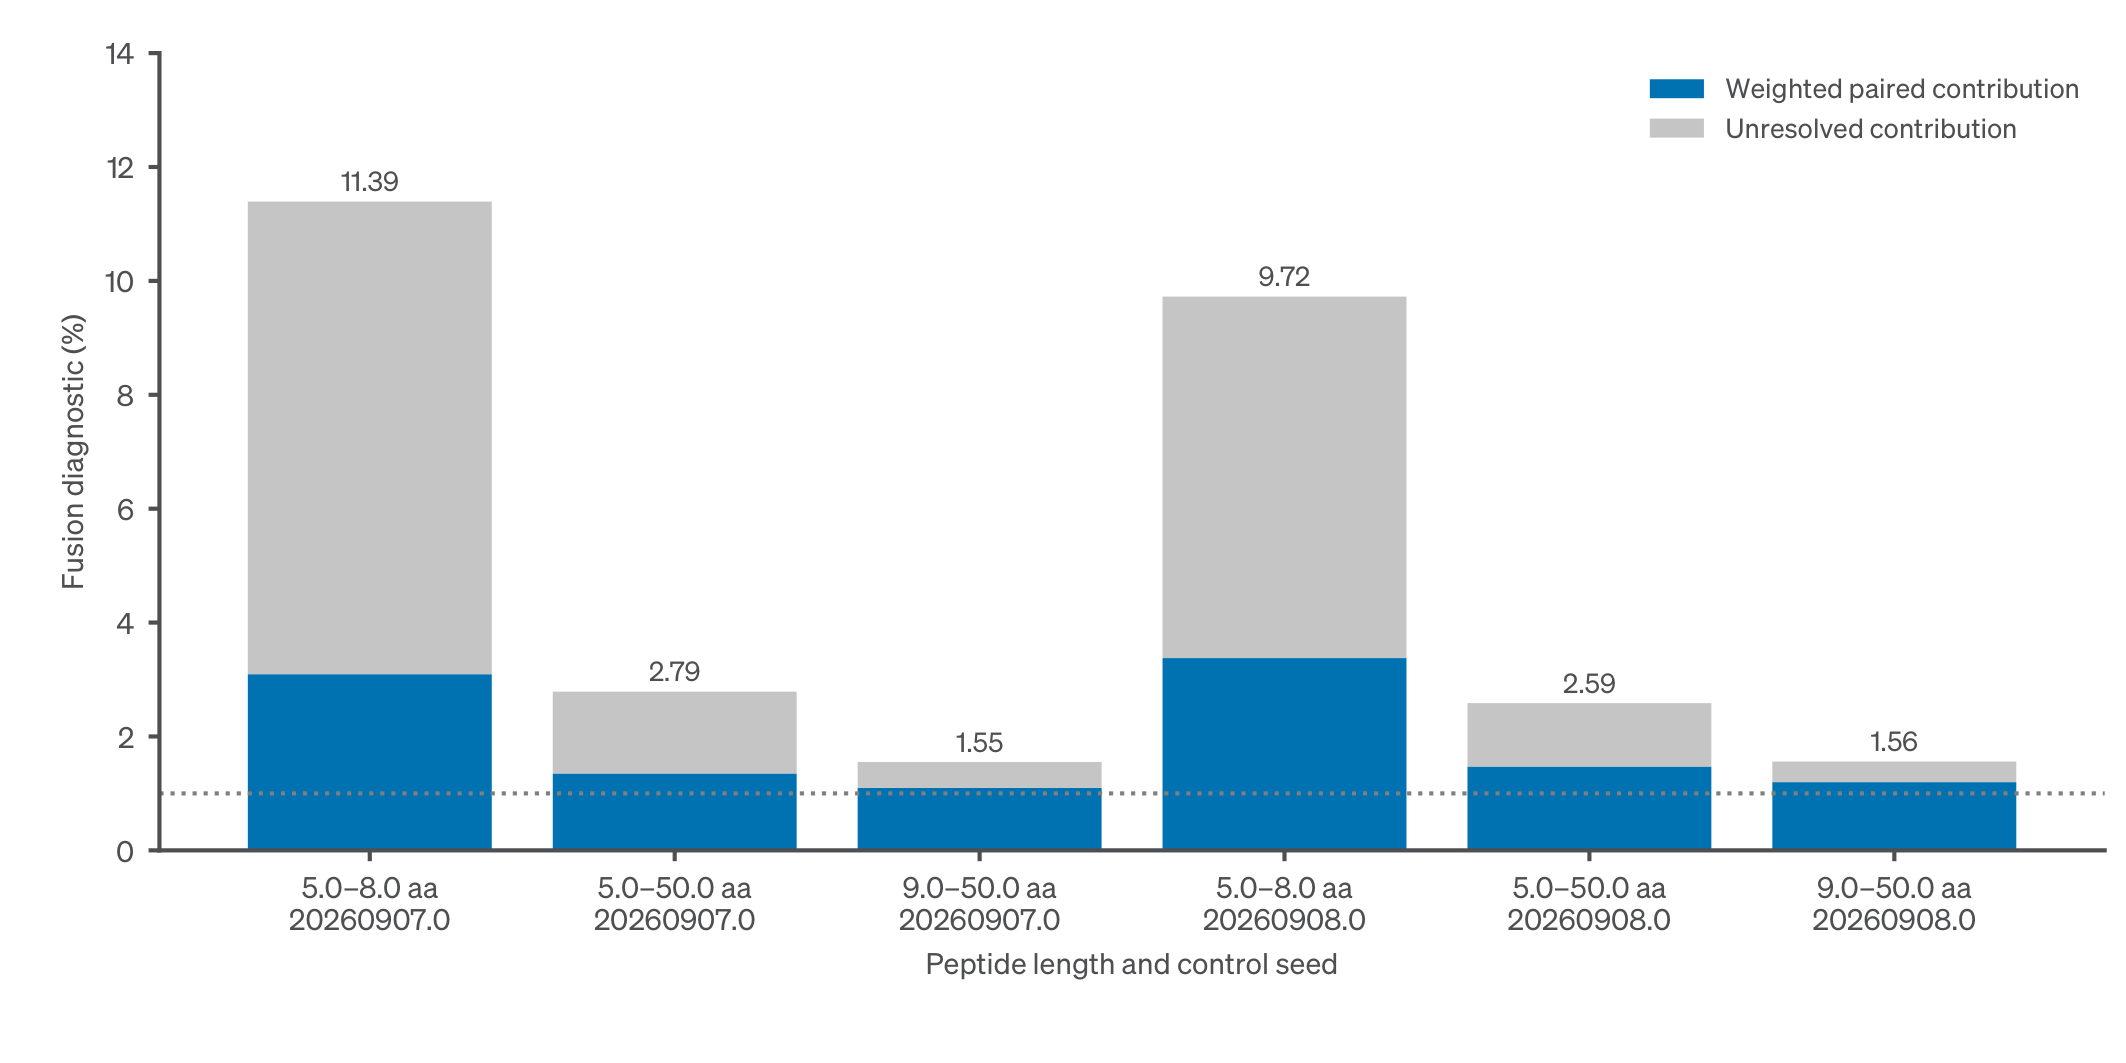

{'unmatched_rows': 0,
 'n': 0.0,
 'E': 0.0,
 'E0': 0.0,
 'B': 0.0,
 'q_ties': 0.0,
 'paired_numerator': 0.0,
 'U': 0.0,
 'paired_pct': 0.0,
 'unresolved_pct': 5.551115123125783e-17,
 'total_pct': 1.7763568394002505e-15,
 'unresolved_share_pct': 0.0}

,seed,min,max,n,E,E0,B,q_ties,paired_numerator,U,paired_pct,unresolved_pct,total_pct,unresolved_share_pct,acquisitions
0,20260907,5,8,40473,684,512,28,0,1252,3359,3.093420,8.299360,11.392780,72.847538,15
1,20260907,5,50,322551,2484,1696,87,13,4354,4633,1.349864,1.436362,2.786226,51.552242,15
2,20260907,9,50,282078,1800,1184,59,13,3102,1274,1.099696,0.451648,1.551344,29.113346,15
3,20260908,5,8,40537,743,562,32,0,1369,2573,3.377162,6.347288,9.724449,65.271436,15
4,20260908,5,50,322769,2689,1827,118,27,4752,3594,1.472260,1.113490,2.585750,43.062545,15
5,20260908,9,50,282232,1946,1265,86,27,3383,1021,1.198659,0.361759,1.560418,23.183470,15


In [6]:
png = panels.figure_continued(T, OUT)
display(Image(filename=str(png), width=700))
dec = panels.stat_cont_fusion_decomposition(T["fusion_acquisition_components"])
display(panels.compare_frames(dec.drop(columns="acquisitions"), T["fusion_decomposition_current375"], ["seed", "min", "max"]))
display(dec)

## Checks and numbers

In [7]:
import os
from tools.check_pixels import compare
if os.environ.get("FASTALAKE_FONT_DIR") or os.environ.get("FL_STYLE_DIR"):
    for name in ["SFig05", "SFig05_continued"]:
        r = compare(OUT / f"{name}.png", UNIT / "expected" / f"{name}_v30.png", UNIT / "checks" / f"{name}_v30", dpi=300)
        print(name, r["verdict"], r["differing_pixels"])
else:
    print("pixel checks SKIPPED: fonts absent")
for key, value in panels.numbers(T):
    print(f"{key}\t{value!r}")

SFig05 IDENTICAL 0


SFig05_continued IDENTICAL 0
L30 donor median 5-50 %	np.float64(0.9958145754310967)
L30 donor median 9-50 %	np.float64(0.48933836622051824)
L45 CAMPI 9-50 mean of seeds %	np.float64(1.5558811668573982)
L45 seeds	2
L46 baseline self mean %	np.float64(1.0071627352669799)
L46 baseline fixed mean %	np.float64(1.24717094486794)
L46 stress self mean %	np.float64(1.90897138538672)
L46 stress self-independent pp	np.float64(0.71183286846378)
L227 q	0.01
L227 self-selected acquisitions	5
L227 donor-selected acquisitions	58
L227 seeds per acquisition	3
L227 mixtures per regime	12
L227 nominal line %	1
L229 CAMPI acquisitions per seed	15
L229 q	0.01
L229 nominal line %	1
L367 seeds	2
L367 5-50 total min %	np.float64(2.585750180469624)
L367 5-50 total max %	np.float64(2.7862260541743784)
L367 9-50 total min %	np.float64(1.5513439545090366)
L367 9-50 total max %	np.float64(1.5604183792057598)
L367 5-8 paired min %	np.float64(3.093420304894621)
L367 5-8 paired max %	np.float64(3.377161605446876)
L367